# AgentSmith: Multi-Bank Fraud Detection with LangGraph

Fraudsters move money in a circle across several banks so that no single bank sees the pattern. AgentSmith looks
at all three banks at once. Given one alert transaction it:

1. **Loads** the transaction and **detects** the payment chain it belongs to
2. **Enriches** the chain with three **bank analyst sub-agents** (a Deep Agent), one per bank, run in parallel
3. **Scores** the risk with transparent rules (circular movement, amount decrement, new accounts, ...) plus **learned
   rules** that an evaluation loop proposed and validated, and a memory boost for accounts tied to past confirmed fraud
4. **Routes**: a score of 70 or more **pauses for a human analyst**, anything lower is auto-cleared
5. **Writes** a plain-English audit memo

**User:** the fraud investigator at the receiving bank who gets the alert and decides investigate or clear.

In this notebook you will run the graph locally, handle the human-in-the-loop pause, publish a labelled dataset to
LangSmith, measure what seeing all three banks is worth, let an evaluation loop improve the rules, and call the
version deployed on LangSmith.

## Step 0: Setup

Copy `.env.example` to `.env` in the repo root and fill in your LangSmith key and workspace. The bank analyst
sub-agents call the model through the gateway; tracing, datasets and evals use LangSmith.

In [21]:
# Notebook only: let Python find `agent.py` and the `utils/` and `tools/` folders.
# This notebook lives in 04_agentsmith/modules/, so the 04_agentsmith folder is one level up.
import sys
from pathlib import Path

project_root = Path().resolve().parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

In [22]:
from dotenv import load_dotenv

load_dotenv(project_root.parent / ".env")

True

## Step 1: Look at the data

Three banks each hold their own transactions. `fraud_labels.jsonl` is the ground truth, one label per payment chain.

The sample uses stable pseudonymous subject references (`SUBJECT-*`) instead of names; no re-identification map is stored. Dates and amounts are synthetic demo values retained for pattern analysis. These references remain linkable within this demo, so this is pseudonymization, not anonymization.

In [23]:
import json

from utils import db

print(db.table("banks"))
for bank in ["bank_a", "bank_b", "bank_c"]:
    print(bank, len(db.table(f"{bank}/transactions")), "transactions")

labels = db.table("fraud_labels")
for label in labels:
    print(label.get("chain_id") or label.get("transaction_id"), label["label"], label["pattern"])

[{'bank_id': 'BANK-A', 'name': 'Albion Bank', 'country': 'GB', 'risk_tier': 'low', 'data_dir': 'bank_a'}, {'bank_id': 'BANK-B', 'name': 'Bridgewater Bank', 'country': 'GB', 'risk_tier': 'medium', 'data_dir': 'bank_b'}, {'bank_id': 'BANK-C', 'name': 'Crown Financial', 'country': 'GB', 'risk_tier': 'medium', 'data_dir': 'bank_c'}]
bank_a 14 transactions
bank_b 13 transactions
bank_c 13 transactions
CHAIN-001 fraud circular
CHAIN-002 fraud circular
CHAIN-003 fraud circular
CHAIN-004 fraud layering
CHAIN-005 fraud layering
CHAIN-006 legitimate None
CHAIN-007 legitimate None
CHAIN-008 legitimate None
TXN-A-010 legitimate None


## Step 2: The graph

```
START -> load_trigger -> detect_chain -> enrich_banks -> score_risk
              (Deep Agent: bank-a / bank-b / bank-c analysts)  |
                                          score >= 70 -> human_review --+
                                          score <  70 -> auto_clear   --+-> write_audit -> END
```

The nodes live in `utils/nodes.py`, the analysts in `sub_agents.py`, the cross-bank lookups in `tools/network.py`
and the learned rules in `utils/rules.py`. A human pause needs a checkpointer when you run locally (LangGraph
Platform adds one when deployed), so we compile a local copy with in-memory ones.

Three run-time options (the agent's *context*) make experiments easy to run:

| Option | Values | Meaning |
|---|---|---|
| `visibility` | `collective` / `single_bank` | all three banks, or only the alert's own bank (how banks work today) |
| `use_learned_rules` | `True` / `False` | with or without `data/learned_rules.json` |
| `enrichment` | `llm` / `basic` | Deep Agent analysts, or deterministic checks (fast, no model calls) |

In this notebook we use `enrichment="basic"` so the cells run in seconds. The deployed runs use the real analysts.

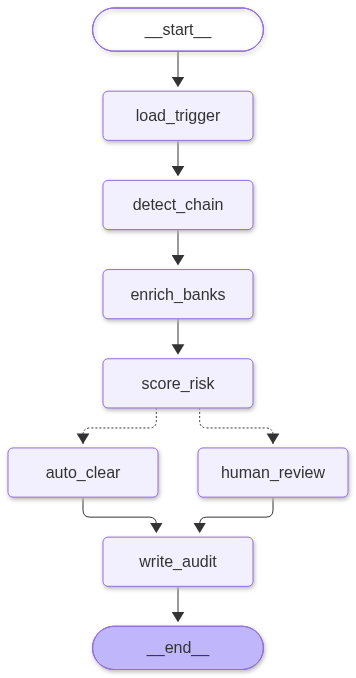

In [24]:
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.store.memory import InMemoryStore

from agent import build_agent

local_agent = build_agent(checkpointer=InMemorySaver(), store=InMemoryStore())
FAST = {"enrichment": "basic", "notify": False}  # swap for {"notify": False} to use the real Deep Agent analysts; notify=False never posts to Slack
local_agent

## Step 3: A fraud alert pauses for a human

`TXN-A-001` is the first leg of `CHAIN-001`, a GBP 5,000 round trip A -> B -> C -> A in under five minutes.

In [25]:
config = {"configurable": {"thread_id": "demo-chain-001"}}
result = local_agent.invoke({"alert_transaction_id": "TXN-A-001"}, config, context=FAST)

print("risk_score:", result["risk_score"])
for reason in result["risk_reasons"]:
    print(" -", reason)
print("paused for human:", "__interrupt__" in result)

risk_score: 60
 - circular fund movement: 6 legs returning to origin in 292s
 - transaction amounts exceed account holders' usual spending range
paused for human: False


If the risk score reached 70 or above, the graph paused at `human_review`. Resume it with the analyst's decision using `Command(resume=...)`. If the score was below 70 the agent auto-cleared and the cell below is a no-op.

In [17]:
from langgraph.types import Command

final = local_agent.invoke(
    Command(resume={"decision": "investigate", "notes": "Classic round trip, escalate to MLRO."}), config, context=FAST
)
print(final["audit_memo"])

Alert: TXN-A-001 | Chain: CHAIN-001 | Banks: BANK-A, BANK-B, BANK-C
Legs: 6 | Entry: £5,000.00 | Exit: £4,802.00
Risk score: 60/100
Risk factors: circular fund movement: 6 legs returning to origin in 292s; transaction amounts exceed account holders' usual spending range
  BANK-C: The account is 15 days old, and all six transactions exceed three times its usual upper amount of GBP 200. Across three chains, incoming funds are followed by outgoing transfers within 46–108 seconds, indicating a repeated rapid pass-through pattern.
Decision: CLEAR (by agent)


## Step 4: A legitimate alert is auto-cleared

`CHAIN-007` is a supplier invoice settlement between established accounts.

In [27]:
result = local_agent.invoke(
    {"alert_transaction_id": "TXN-A-013"}, {"configurable": {"thread_id": "demo-chain-007"}}, context=FAST
)
print(result["audit_memo"])

Alert: TXN-A-013 | Chain: CHAIN-007 | Banks: BANK-A, BANK-C
Legs: 2 | Entry: £75,000.00 | Exit: £75,000.00
Risk score: 20/100
Risk factors: foreign-national account holder(s) in chain; transaction amounts exceed account holders' usual spending range
  BANK-C: The account holder is based in Ireland, and both transfers exceed three times the account’s usual amount range upper limit of £6,000. The account is not new, and the transactions are not within seconds of each other.
Decision: CLEAR (by agent)


## Step 5: What is seeing all three banks worth?

Each bank on its own only sees its own legs of a chain, which is how fraud investigation works today. We run the
same 40 alerts four ways: `single_bank` vs `collective`, each with the original rules only (`baseline`) and with the
learned rules. A fraud *chain* counts as caught if any of its alerts is routed to a human.

In [28]:
from collections import defaultdict

by_chain = {l["chain_id"]: l for l in labels if l.get("chain_id")}
by_txn = {l["transaction_id"]: l for l in labels if l.get("transaction_id")}


def sweep(visibility: str, learned: bool) -> dict:
    scores = defaultdict(list)
    for bank_dir in ["bank_a", "bank_b", "bank_c"]:
        for txn in db.table(f"{bank_dir}/transactions"):
            out = local_agent.invoke(
                {"alert_transaction_id": txn["transaction_id"]},
                {"configurable": {"thread_id": f"{visibility}-{learned}-{txn['transaction_id']}"}},
                context={**FAST, "visibility": visibility, "use_learned_rules": learned},
            )
            scores[txn["chain_id"]].append(out["risk_score"])
    return scores


for visibility in ["single_bank", "collective"]:
    for learned in [False, True]:
        scores = sweep(visibility, learned)
        caught = sum(1 for c, v in scores.items() if c and by_chain[c]["label"] == "fraud" and max(v) >= 70)
        print(f"{visibility:12} learned_rules={learned!s:5}  fraud chains caught: {caught}/5")

single_bank  learned_rules=False  fraud chains caught: 3/5


KeyboardInterrupt: 

**What this shows:** no single bank catches any of the five fraud chains with the original rules. With the
collective view the circular chains (001-003) are caught, but the two *layering* chains (004, 005) are missed. The
learned rules in the next steps close that gap.

## Step 6: Publish the dataset to LangSmith

`evals/run_eval.py` builds one example per transaction (inputs: `alert_transaction_id`; reference outputs: chain,
label, pattern, expected decision) with a split per bank, and uploads it as the `agentsmith-fraud-alerts` dataset.
It is idempotent: if the dataset exists it is reused.

In [29]:
from langsmith import Client

from evals.run_eval import DATASET, ensure_dataset

client = Client()
dataset = ensure_dataset(client)
print(dataset.name, dataset.id, "examples:", len(list(client.list_examples(dataset_id=dataset.id))))

Dataset 'agentsmith-fraud-alerts' already exists, reusing it.
agentsmith-fraud-alerts 4dadf5ba-31c2-47a9-bbf4-d3252a3a966f examples: 40


## Step 7: Evaluate the agent

We score each run with code evaluators defined in `evals/run_eval.py`:

| Evaluator | Meaning |
|---|---|
| `flag_matches_label` | the agent flagged exactly the fraud cases |
| `false_negative` | fraud that was **not** flagged (the costly miss) |
| `false_positive` | legitimate activity that **was** flagged |
| `chain_detected` | the right payment chain was found |
| `reasons_for_flagged` | a flagged case always explains why |

Here we evaluate the *local* graph. A flagged run is left paused rather than resumed, so "flagged" means the agent
asked for a human.

In [31]:
from langsmith import evaluate

from evals.run_eval import (
    chain_detected,
    false_negative,
    false_positive,
    flag_matches_label,
    reasons_for_flagged,
)


def local_target(inputs: dict) -> dict:
    thread = {"configurable": {"thread_id": f"eval-{inputs['alert_transaction_id']}"}}
    out = local_agent.invoke(inputs, thread, context=FAST)
    return {
        "chain_id": out.get("chain_id"),
        "risk_score": out["risk_score"],
        "risk_reasons": out["risk_reasons"],
        "flagged": "__interrupt__" in out,
    }


# Set to True to create a new experiment in LangSmith (about a minute).
RUN_LOCAL_EVAL = False

if RUN_LOCAL_EVAL:
    results = evaluate(
        local_target,
        data=DATASET,
        evaluators=[flag_matches_label, false_negative, false_positive, chain_detected, reasons_for_flagged],
        experiment_prefix="agentsmith-local",
        max_concurrency=4,
    )

Open the dataset in the LangSmith console (Datasets & Experiments -> `agentsmith-fraud-alerts` -> Experiments) to
compare experiments side by side.

## Step 8: Call the deployed agent

The same graph is deployed on LangSmith. Set `DEPLOYMENT_URL` to your deployment's URL (shown in the console under
Deployments). `run_eval.py` also accepts `--url` to run the whole evaluation against the deployment from the
command line. Deployment traces appear in the `agentsmith-production` project.

In [32]:
import os

from langgraph_sdk import get_sync_client

DEPLOYMENT_URL = "https://agentsmith-1a092d08c74758e386290b904b63e00e.us.langgraph.app"

remote = get_sync_client(url=DEPLOYMENT_URL, api_key=os.environ["LANGSMITH_API_KEY"])
thread = remote.threads.create()
remote.runs.wait(thread["thread_id"], "agentsmith", input={"alert_transaction_id": "TXN-A-001"})

state = remote.threads.get_state(thread["thread_id"])
print("risk_score:", state["values"]["risk_score"], "| waiting on:", state["next"])

KeyboardInterrupt: 

## Step 9: The improvement loop

`evals/improve.py` closes the loop between evaluation and the agent:

1. score every labelled alert and collect the **missed fraud chains**
2. an LLM proposes up to three rules in a **typed schema** (`fan_out`, `fan_in`, `split_forward`), never code
3. the candidate is scored on the whole dataset as a **LangSmith experiment** (`agentsmith-improve-iterN`)
4. it is accepted only if it catches **more** fraud chains with **zero** new false positives, otherwise the failure is
   fed back to the LLM
5. accepted rules are written to `data/learned_rules.json` and shipped with the next deployment

Run it with `uv run python -m evals.improve` (add `--dry-run` to preview). The rules in the repo came from this loop.

**Human decisions close the flywheel.** Every time an analyst confirms a case via human review, `write_audit`
appends the confirmed label to `data/fraud_labels.jsonl`. The next time `improve.py` runs it sees these new
confirmed cases as part of its training set — so the rules get better as analysts review more alerts. The loop is:

> *alert → human review → confirmed label → `improve.py` → better rules → fewer alerts for humans to review*

In [33]:
from utils.rules import load_learned_rules

for rule in load_learned_rules():
    print(rule["rule_type"], f"min_legs={rule['min_legs']} window={rule['window_seconds']}s", f"+{rule['points']}")
    print("   ", rule["rationale"])

fan_out min_legs=3 window=120s +60
    Captures rapid repeated dispersal from one account while excluding the legitimate chain with only two outgoing transfers.
split_forward min_legs=2 window=135s +35
    Captures an account that rapidly forwards nearly all of a received amount in multiple transfers.


## Step 10: Online evaluators and next steps

- **Online evaluators** score live traces in `agentsmith-production` with no labels (for example "a flagged run
  must have reasons"). Add them in the console: project -> New -> Evaluator, filter to root runs.
- **Generalisation**: the dataset has only five fraud chains, and the loop saw all of them. Add held-out synthetic
  chains the loop never sees before trusting the numbers.
- Redeploy after changing rules: `langgraph deploy --name agentsmith --remote`.